# Lab - EDA Univariate Analysis: Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights.

**Dataset**: [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)

## Imports & Load Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
plt.show()

In [3]:
amazon_uk_product_df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [4]:
amazon_uk_product_df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
amazon_uk_product_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [7]:
amazon_uk_product_df.shape

(2443651, 9)

In [17]:
amazon_uk_product_df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [18]:
amazon_uk_product_df.duplicated().sum()

np.int64(0)

In [19]:
amazon_uk_product_df.nunique()

uid                  2443651
asin                 2222742
title                2077591
stars                     42
reviews                19446
price                  82916
isBestSeller               2
boughtInLastMonth         25
category                 296
dtype: int64

In [23]:
def all_value_counts(amazon_uk_product_df):
    for column in amazon_uk_product_df.columns:
        print(f"--- {column} ---")
        print(amazon_uk_product_df[column].value_counts())
        print()
all_value_counts(amazon_uk_product_df)

--- uid ---
uid
1          1
1833462    1
1833464    1
1833465    1
1833466    1
          ..
889449     1
889450     1
889451     1
889452     1
2828593    1
Name: count, Length: 2443651, dtype: int64

--- asin ---
asin
B083L94P36    7
B08CS1RJYK    7
B07MVP6T9C    7
B0884G1PZ5    7
B08BDG1DR2    7
             ..
B004BW8TYC    1
B0BPMBYBKL    1
B0BV24Z9M4    1
B08NVLFT7M    1
B08P3W9B3T    1
Name: count, Length: 2222742, dtype: int64

--- title ---
title
OYhmc Portable Pedal Exerc                                                                                                                                                                        723
ScibOr Outdoor Sleeveless Fishing Vest                                                                                                                                                            322
SHOPPRO Kids Golf Shoes Set, White, with Shoes Bag, UV Sun Protection Arm Sleeves, Golf Pro Cap and Instant Cooling Towel, Outdoor Sneakers, Gi

In [29]:
amazon_uk_product_df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [30]:
list(set(amazon_uk_product_df.dtypes.tolist()))

[dtype('bool'), dtype('O'), dtype('float64'), dtype('int64')]

In [31]:
amazon_uk_product_df.select_dtypes("number").columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')

In [32]:
amazon_uk_product_df.select_dtypes("number").nunique().sort_values(ascending=False)

uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64

In [35]:
potential_categorical_from_numerical = amazon_uk_product_df.select_dtypes("number").loc[:, amazon_uk_product_df.select_dtypes("number").nunique() < 30]
potential_categorical_from_numerical

,boughtInLastMonth
0,0
1,0
2,0
3,0
4,0
...,...
2443646,0
2443647,0
2443648,0
2443649,0


In [37]:
amazon_uk_product_df.select_dtypes("object").columns

Index(['asin', 'title', 'category'], dtype='object')

In [38]:
amazon_uk_product_df.select_dtypes("object").nunique().sort_values(ascending=False)

asin        2222742
title       2077591
category        296
dtype: int64

In [39]:
amazon_uk_product_df_categorical = pd.concat([amazon_uk_product_df.select_dtypes("object"), potential_categorical_from_numerical], axis=1)

amazon_uk_product_df_numerical = amazon_uk_product_df.select_dtypes("number").drop(columns=potential_categorical_from_numerical.columns)

---
## Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

### 1.1 Frequency Table
Generate a frequency table for the product `category` column.
Which are the top 5 most listed product categories?

In [44]:
category_frequency_table = amazon_uk_product_df["category"].value_counts()

category_proportion_table = amazon_uk_product_df["category"].value_counts(normalize=True)
print(category_frequency_table.head(5))
print()
print(category_proportion_table.head(5))

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

category
Sports & Outdoors                         0.342219
Beauty                                    0.007903
Handmade Clothing, Shoes & Accessories    0.007869
Bath & Body                               0.007813
Birthday Gifts                            0.007766
Name: proportion, dtype: float64


In [46]:
frequency_table = pd.crosstab(index=amazon_uk_product_df_categorical["category"], columns="count")

frequency_table

col_0,count
category,
3D Printers,248
3D Printing & Scanning,4067
Abrasive & Finishing Products,250
Action Cameras,1697
Adapters,254
...,...
Wind Instruments,250
Window Treatments,239
Women,17772


In [48]:
(frequency_table / frequency_table.sum()).round(4).sort_values("count", ascending=False).head(10)

col_0,count
category,
Sports & Outdoors,0.3422
"Handmade Clothing, Shoes & Accessories",0.0079
Beauty,0.0079
Manicure & Pedicure Products,0.0078
Birthday Gifts,0.0078
Bath & Body,0.0078
Skin Care,0.0077
Make-up,0.0077
Hair Care,0.0077


### 1.2 Bar Chart
Display the distribution of products across different categories using a bar chart.
If the full chart is hard to read, use a subset of top categories.

/var/folders/lg/5zr61f512tn2t5yg6hpddmsm0000gn/T/ipykernel_2508/1682187362.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.index, y=top_categories.values, palette="Set3")


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Beauty'),
  Text(2, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(3, 0, 'Bath & Body'),
  Text(4, 0, 'Birthday Gifts'),
  Text(5, 0, 'Manicure & Pedicure Products'),
  Text(6, 0, 'Skin Care'),
  Text(7, 0, 'Make-up'),
  Text(8, 0, 'Hair Care'),
  Text(9, 0, 'Fragrances'),
  Text(10, 0, 'Handmade Gifts'),
  Text(11, 0, 'Handmade Home Décor'),
  Text(12, 0, 'Luggage and travel gear'),
  Text(13, 0, 'Handmade Jewellery'),
  Text(14, 0, 'Handmade Artwork'),
  Text(15, 0, 'Women'),
  Text(16, 0, 'Handmade Home & Kitchen Products'),
  Text(17, 0, 'Handmade Kitchen & Dining'),
  Text(18, 0, 'Men'),
  Text(19, 0, 'Baby')])

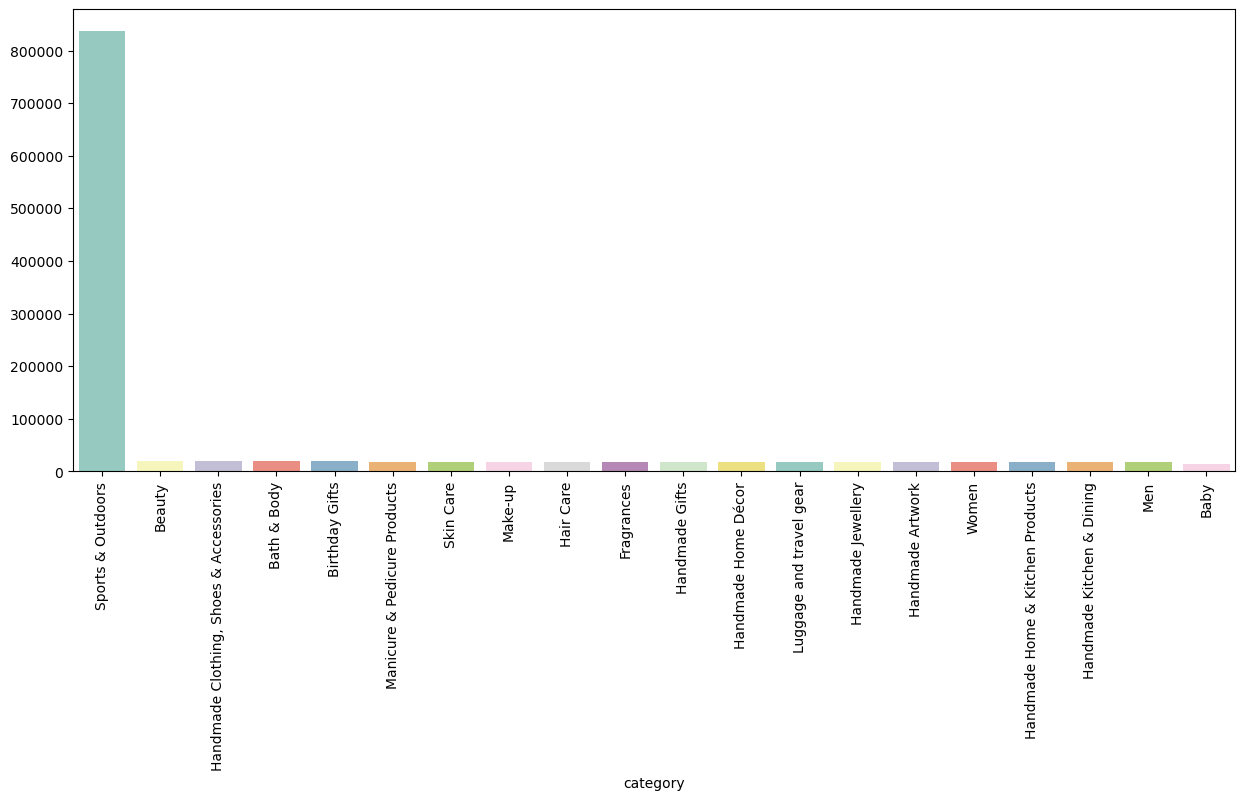

In [53]:
top_categories = category_frequency_table.head(20)
plt.figure(figsize=(15, 6))
sns.barplot(x=top_categories.index, y=top_categories.values, palette="Set3")
plt.xticks(rotation=90)

/var/folders/lg/5zr61f512tn2t5yg6hpddmsm0000gn/T/ipykernel_2508/2602689643.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories_filtered.index, y=top_categories_filtered.values, palette="Set3")


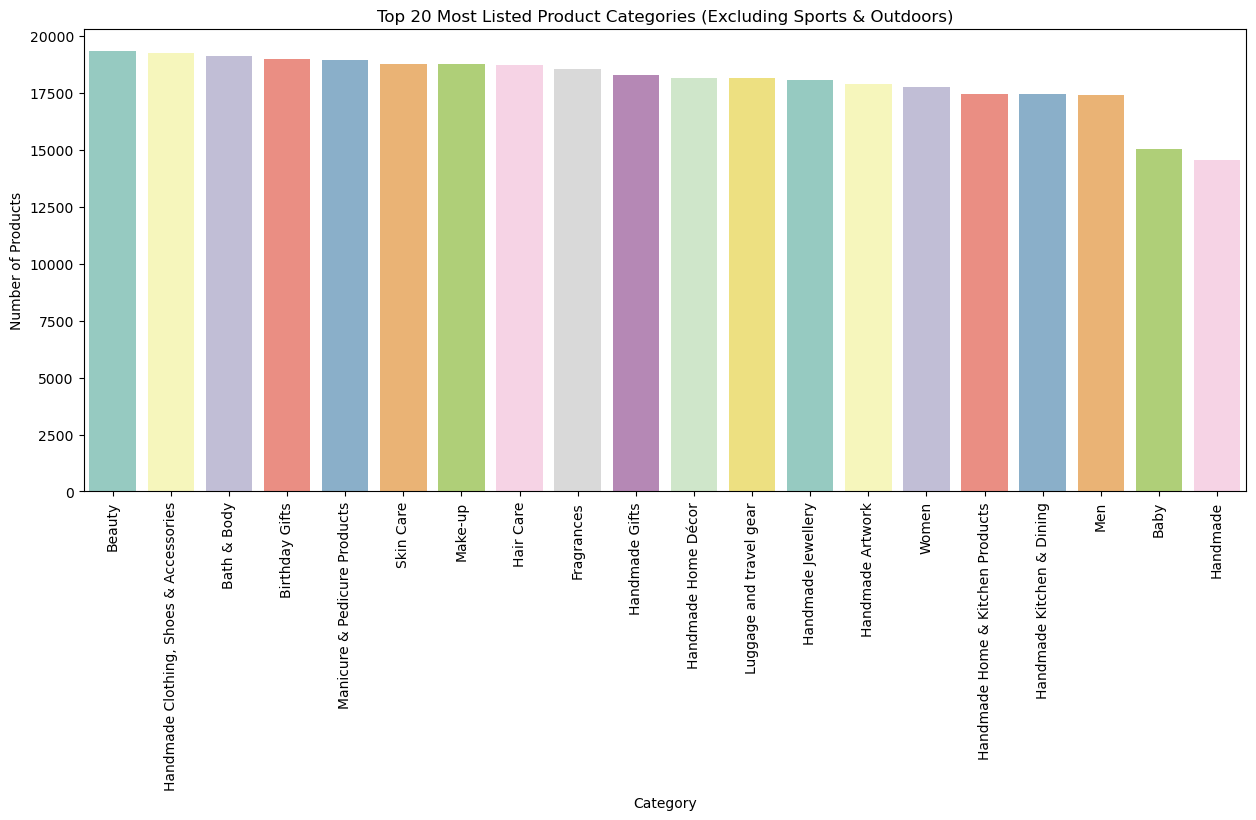

In [54]:
top_categories_filtered = category_frequency_table[category_frequency_table.index != "Sports & Outdoors"].head(20)

plt.figure(figsize=(15, 6))
sns.barplot(x=top_categories_filtered.index, y=top_categories_filtered.values, palette="Set3")
plt.xticks(rotation=90)
plt.title("Top 20 Most Listed Product Categories (Excluding Sports & Outdoors)")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.show()

### 1.3 Pie Chart
For a subset of top categories, visualize their proportions using a pie chart.
Does any category dominate the listings?

<Axes: ylabel='count'>

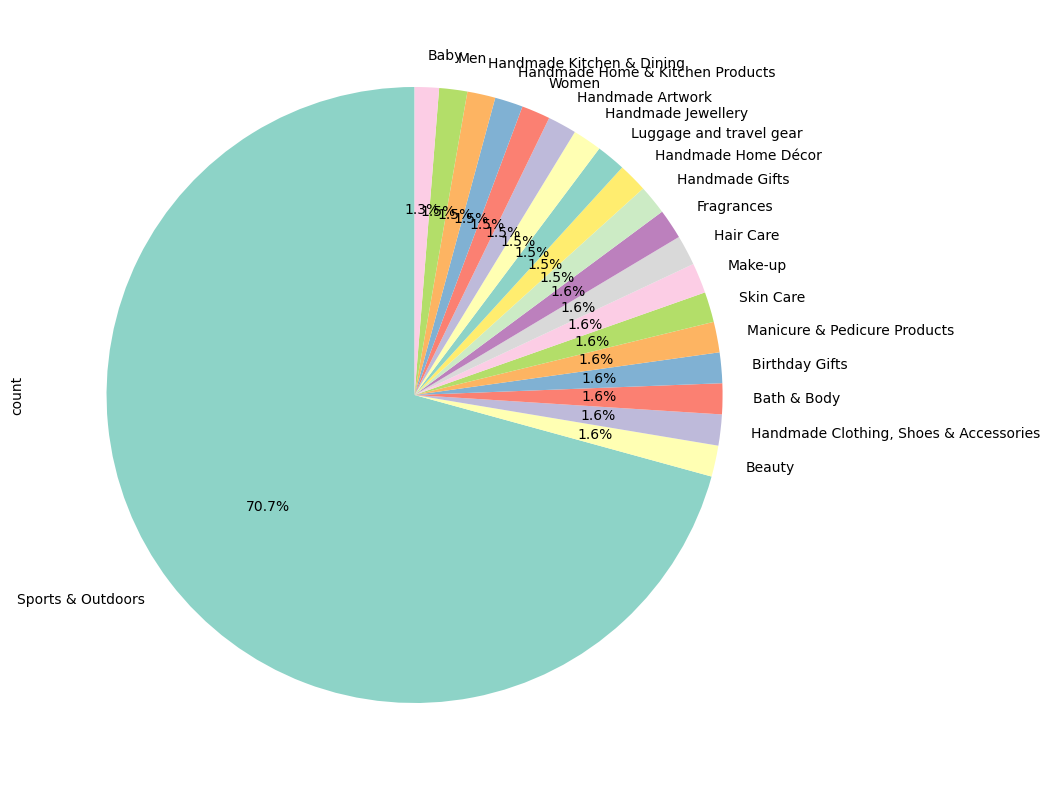

In [56]:
plt.figure(figsize=(10, 10))
top_categories.plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"))

**Insights (write your observations here):**

- The dataset contains 296 unique product categories across 2.4 million listings.
- Sports & Outdoors is by far the most dominant category, accounting for 70.7% of all product listings with over 836,000 products — significantly more than any other category.
- The remaining categories are fairly evenly distributed, each representing around 1.5-1.6% of listings.
- No other single category comes close to challenging Sports & Outdoors in terms of listing volume.
- Business implication: Amazon UK's marketplace is heavily concentrated in Sports & Outdoors. Businesses in other categories face a less crowded marketplace, which could be an opportunity for visibility.


---
## Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

In [57]:
amazon_uk_product_df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


### 2.1 Measures of Centrality
Calculate the mean, median, and mode for the `price` column.
What is the average price point? How does it compare with the most common price (mode)?

In [61]:
mean_price = amazon_uk_product_df['price'].mean()
median_price = amazon_uk_product_df['price'].median()
mode_price = amazon_uk_product_df['price'].mode()[0]

mean_price, median_price, mode_price

(np.float64(89.24380943923661), 19.09, np.float64(9.99))

### 2.2 Measures of Dispersion
Determine the variance, standard deviation, range, and interquartile range (IQR) for product `price`.
How varied are the product prices? Are there any indicators of a significant spread?

In [62]:
variance_price = amazon_uk_product_df['price'].var()
std_dev_price = amazon_uk_product_df['price'].std()
min_price = amazon_uk_product_df['price'].min()
max_price = amazon_uk_product_df['price'].max()
range_price = max_price - min_price
quantiles_price = amazon_uk_product_df['price'].quantile([0.25, 0.5, 0.75])

variance_price, std_dev_price, min_price, max_price, range_price, quantiles_price

(119445.4853225653,
 345.6088617535223,
 0.0,
 100000.0,
 100000.0,
 0.25     9.99
 0.50    19.09
 0.75    45.99
 Name: price, dtype: float64)

### 2.3 Histogram - Price Distribution
Plot a histogram to visualize the distribution of product prices.
Is there a specific price range where most products fall?
If the chart is hard to read, explain why and how it could be solved.

<Axes: xlabel='price', ylabel='Count'>

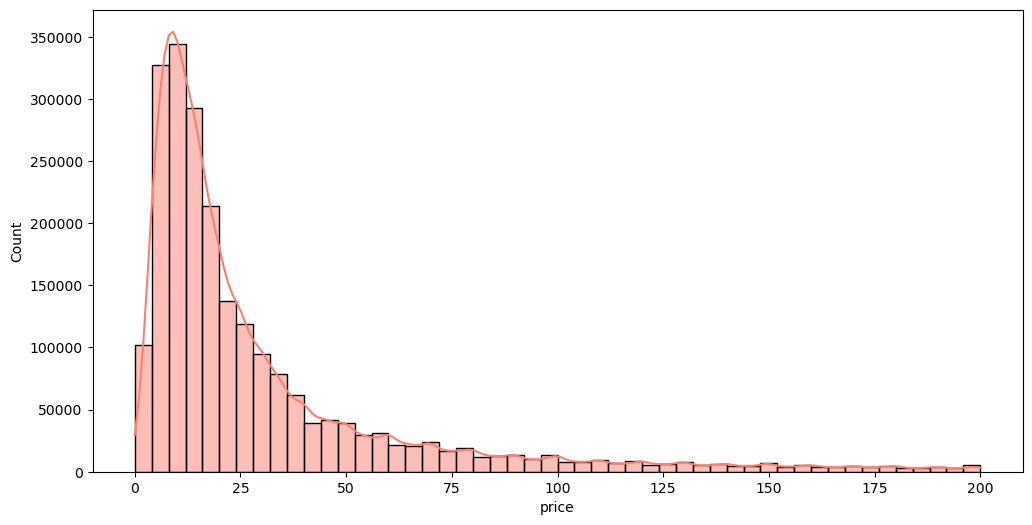

In [67]:
price_filtered = amazon_uk_product_df[amazon_uk_product_df["price"] < 200]["price"]

plt.figure(figsize=(12, 6))
sns.histplot(price_filtered, kde=True, bins=50, color="salmon")

### 2.4 Box Plot - Price Outliers
Use a box plot to showcase the spread and potential outliers in product pricing.
Are there products priced significantly higher than the rest?

<Axes: ylabel='price'>

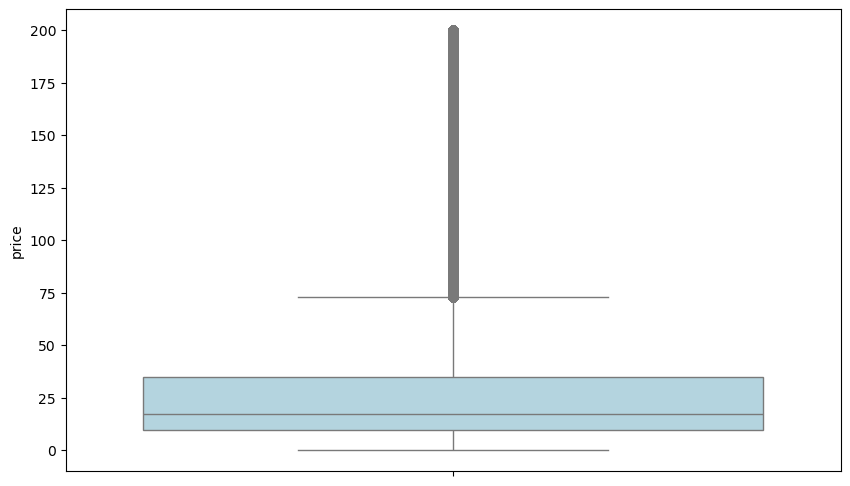

In [71]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=price_filtered, color="lightblue")

**Insights (write your observations here):**

- The mean price (£89.24) is significantly higher than the median (£19.09) and mode (£9.99), indicating a strong right skew caused by expensive outlier products.
- The most common price point is £9.99 — a classic psychological pricing strategy used by sellers.
- The standard deviation (£345.61) is much larger than the mean (£89.24), confirming extreme variability in prices.
- The histogram confirms that the majority of products are priced under £25, with a long tail extending toward higher prices.
- The box plot reveals a large number of outliers above £75, which explains the inflated mean.
- Business implication: Most products on Amazon UK are affordable (under £25), but premium and luxury products create significant price spread. Sellers targeting the mass market should price around £10-£20 to align with the most common price points.


---
## Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

### 3.1 Measures of Centrality
Calculate the mean, median, and mode for the `stars` column.
How do customers generally rate products? Is there a common trend?

In [ ]:
mean_rating = amazon_uk_product_df["stars"].mean()
median_rating = amazon_uk_product_df["stars"].median()
mode_rating = amazon_uk_product_df["stars"].mode()[0]

mean_rating, median_rating, mode_rating

(np.float64(4.319160762226911), 4.4, np.float64(4.5))

In [76]:
amazon_uk_product_df["stars"].value_counts().head(10)

stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
Name: count, dtype: int64

In [78]:
stars_filtered = amazon_uk_product_df[amazon_uk_product_df["stars"] > 0]["stars"]

mean_rating = stars_filtered.mean()
median_rating = stars_filtered.median()
mode_rating = stars_filtered.mode()[0]

mean_rating, median_rating, mode_rating

(np.float64(4.319160762226911), 4.4, np.float64(4.5))

### 3.2 Measures of Dispersion
Determine the variance, standard deviation, and interquartile range (IQR) for product `star`.
Are the ratings consistent, or is there a wide variation in customer feedback?

In [82]:
variance_rating = stars_filtered.var()
std_dev_rating = stars_filtered.std()
quantiles_rating = stars_filtered.quantile([0.25, 0.5, 0.75])

variance_rating, std_dev_rating, quantiles_rating

(0.30834337523805183,
 0.5552867504614637,
 0.25    4.1
 0.50    4.4
 0.75    4.6
 Name: stars, dtype: float64)

### 3.3 Shape of the Distribution
Calculate the skewness and kurtosis for the `stars` column.
Are the ratings normally distributed, or do they lean towards higher or lower values?

In [86]:
skewness_rating = stars_filtered.skew()
kurtosis_rating = stars_filtered.kurtosis()

skewness_rating, kurtosis_rating

(np.float64(-2.379568112212799), np.float64(9.78193769066435))

### 3.4 Histogram - Rating Distribution
Plot a histogram to visualize the distribution of product ratings.
Is there a specific rating that is more common?

<Axes: xlabel='stars', ylabel='Count'>

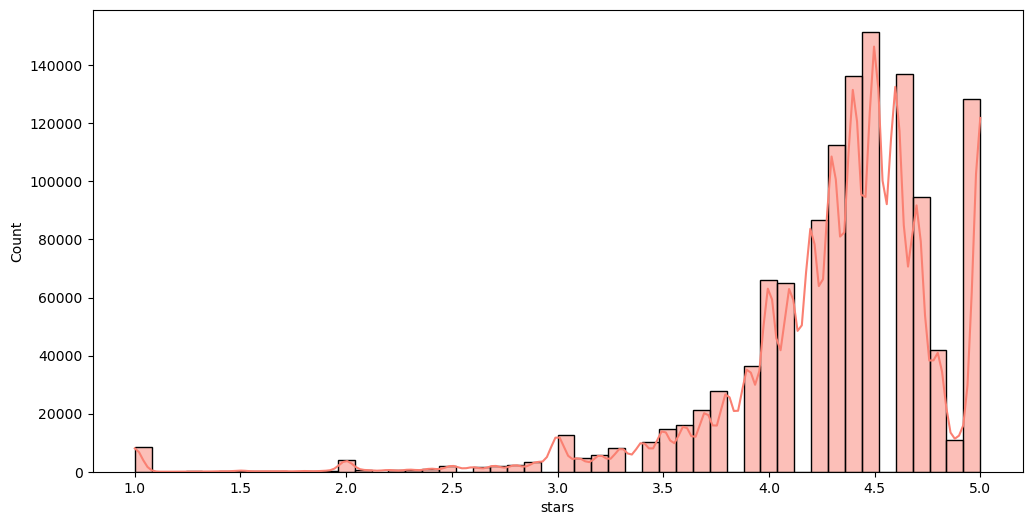

In [87]:
plt.figure(figsize=(12, 6))
sns.histplot(stars_filtered, kde=True, bins=50, color="salmon")

**Insights (write your observations here):**

- 1,225,641 products (50% of the dataset) have a 0.0 rating, meaning they have no reviews yet. These were excluded from the analysis to avoid distortion.
- Among rated products, the mean (4.32), median (4.4), and mode (4.5) are all closely clustered above 4.0 — indicating customers generally rate products very positively on Amazon UK.
- The standard deviation (0.56) and IQR (0.5) are very small, confirming that ratings are highly consistent — most products fall between 4.1 and 4.6 stars.
- Skewness of -2.38 confirms a strong left skew — the majority of products receive high ratings with very few low-rated products.
- Kurtosis of 9.78 indicates a sharp peak around 4.4-4.5 stars with heavy tails — ratings are heavily concentrated in a narrow range.
- The histogram visually confirms all of this — a sharp spike between 4.0-5.0 stars and a small spike at 1.0 for the worst-rated products.
- Business implication: Amazon UK products are generally well-received by customers. New sellers should aim for ratings above 4.0 to be competitive, as this is where the majority of successful products cluster.
